<a href="https://colab.research.google.com/github/ibrahimelkhalilmehimda/Deep-Learning-projects/blob/main/DL_Mask_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install kaggle

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


# importing mask/with_mask data

In [ ]:
!kaggle datasets download -d omkargurav/face-mask-dataset

Dataset URL: https://www.kaggle.com/datasets/omkargurav/face-mask-dataset
License(s): unknown
100% 163M/163M [00:01<00:00, 110MB/s]



In [ ]:
# extrac the compessed data
from zipfile import ZipFile
dataset = '/content/face-mask-dataset.zip'
with ZipFile(dataset,'r') as zip:
  zip.extractall()
  print('data set extracted')

data set extracted


In [ ]:
# extrac the compessed data
from zipfile import ZipFile
dataset = '/content/face-mask-dataset.zip'
with ZipFile(dataset,'r') as zip:
  zip.extractall()
  print('data set extracted')

In [ ]:
!ls

data  face-mask-dataset.zip  sample_data


# importing the dependencies

In [ ]:
import os
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cv2
from google.colab.patches import cv2_imshow
from PIL import Image
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras

In [ ]:
with_mask_filename = os.listdir('/content/data/with_mask')

In [ ]:
print ( len(with_mask_filename))
print(with_mask_filename[0:5])

3725
['with_mask_266.jpg', 'with_mask_874.jpg', 'with_mask_3521.jpg', 'with_mask_902.jpg', 'with_mask_1260.jpg']


In [ ]:
without_mask_filename = os.listdir('/content/data/without_mask')

In [ ]:
print ( len(with_mask_filename))
print(without_mask_filename[-5:])

3828
['without_mask_1038.jpg', 'without_mask_1662.jpg', 'without_mask_2880.jpg', 'without_mask_1692.jpg', 'without_mask_3059.jpg']


#consulting some data

<class 'numpy.ndarray'>
(190, 160, 3)


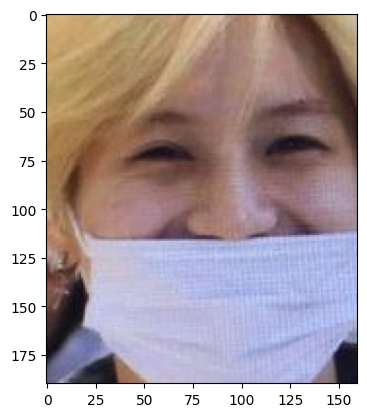

In [ ]:
img = mpimg.imread('/content/data/with_mask/with_mask_266.jpg')
print(type(img))
print(img.shape)
plt.imshow(img)


<class 'numpy.ndarray'>
(276, 183, 3)


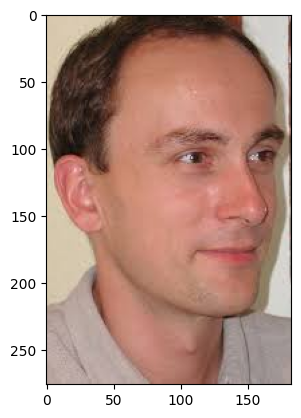

In [ ]:
img = mpimg.imread('/content/data/without_mask/without_mask_2088.jpg')
print(type(img))
print(img.shape)
plt.imshow(img)


# label of classification
0: with out mask
1: with mask

In [ ]:
label = [1]*3725 + [0]*3828

In [ ]:
print (len(label))
print(label[0:5])
print(label[-5:])

7553
[1, 1, 1, 1, 1]
[0, 0, 0, 0, 0]


# image processing ( resize and Convert the images to numpy arrays )


In [ ]:
data=[]
with_mask_path = '/content/data/with_mask/'
without_mask_path = '/content/data/without_mask/'
# processing of wuth mask images
for f in with_mask_filename:
  img = Image.open(with_mask_path + f)
  img = img.resize((128,128))
  img = img.convert('RGB')
  img = np.array(img)
  data.append(img)

# processing of without mask images
for f in without_mask_filename:
  img = Image.open(without_mask_path + f)
  img = img.resize((128,128))
  img = img.convert('RGB')
  img = np.array(img)
  data.append(img)

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


In [ ]:
type(data)

list

In [ ]:
print(data[0])

[[[208 175 121]
  [209 176 122]
  [209 177 120]
  ...
  [198 187 153]
  [198 187 158]
  [200 189 161]]

 [[210 177 124]
  [211 177 124]
  [210 176 122]
  ...
  [201 187 155]
  [202 189 160]
  [201 188 161]]

 [[213 179 127]
  [213 178 126]
  [210 174 122]
  ...
  [198 182 152]
  [200 184 157]
  [199 184 158]]

 ...

 [[ 94  94 124]
  [ 99  98 129]
  [102 101 135]
  ...
  [ 19  21  36]
  [ 20  22  36]
  [ 21  24  37]]

 [[100  99 130]
  [101 101 132]
  [106 105 137]
  ...
  [ 18  19  35]
  [ 19  20  35]
  [ 20  21  34]]

 [[ 96  97 127]
  [ 98  99 130]
  [101 102 133]
  ...
  [ 18  17  33]
  [ 20  19  33]
  [ 20  19  33]]]


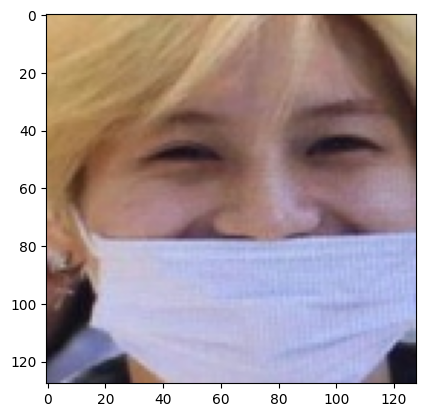

In [ ]:
plt.imshow(data[0])


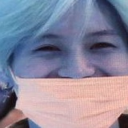

In [ ]:
cv2_imshow(data[0])

In [ ]:
x= np.asarray(data)
y= np.asarray(label)

In [ ]:
print(x.shape)
print(y.shape)

(7553, 128, 128, 3)
(7553,)


# split train test data

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=2)

# scaling data

In [ ]:
x_train_scaled = x_train/255

x_test_scaled = x_test/255

In [ ]:
print(x_train[0])

[[[0 0 0]
  [0 1 3]
  [0 1 4]
  ...
  [0 0 0]
  [0 0 0]
  [1 0 0]]

 [[0 0 0]
  [0 1 3]
  [0 1 4]
  ...
  [0 1 0]
  [0 1 0]
  [0 0 0]]

 [[0 0 0]
  [0 1 3]
  [0 0 3]
  ...
  [0 1 2]
  [0 1 2]
  [0 0 2]]

 ...

 [[2 0 0]
  [1 0 0]
  [1 0 1]
  ...
  [0 1 0]
  [0 1 1]
  [1 2 2]]

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]]


In [ ]:
print(x_train_scaled[0])

[[[0.         0.         0.        ]
  [0.         0.00392157 0.01176471]
  [0.         0.00392157 0.01568627]
  ...
  [0.         0.         0.        ]
  [0.         0.         0.        ]
  [0.00392157 0.         0.        ]]

 [[0.         0.         0.        ]
  [0.         0.00392157 0.01176471]
  [0.         0.00392157 0.01568627]
  ...
  [0.         0.00392157 0.        ]
  [0.         0.00392157 0.        ]
  [0.         0.         0.        ]]

 [[0.         0.         0.        ]
  [0.         0.00392157 0.01176471]
  [0.         0.         0.01176471]
  ...
  [0.         0.00392157 0.00784314]
  [0.         0.00392157 0.00784314]
  [0.         0.         0.00784314]]

 ...

 [[0.00784314 0.         0.        ]
  [0.00392157 0.         0.        ]
  [0.00392157 0.         0.00392157]
  ...
  [0.         0.00392157 0.        ]
  [0.         0.00392157 0.00392157]
  [0.00392157 0.00784314 0.00784314]]

 [[0.         0.         0.        ]
  [0.         0.         0.        ]


# Building the CNN

In [ ]:

model = keras.Sequential()

model.add(keras.layers.Conv2D(32, kernel_size=(3,3), activation='relu', input_shape=(128,128,3)))
model.add(keras.layers.MaxPooling2D(pool_size=(2,2)))


model.add(keras.layers.Conv2D(64, kernel_size=(3,3), activation='relu'))
model.add(keras.layers.MaxPooling2D(pool_size=(2,2)))

model.add(keras.layers.Flatten())

model.add(keras.layers.Dense(128, activation='relu'))
model.add(keras.layers.Dropout(0.5))

model.add(keras.layers.Dense(64, activation='relu'))
model.add(keras.layers.Dropout(0.5))


model.add(keras.layers.Dense(2, activation='sigmoid'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['acc'])

In [ ]:
history = model.fit(x_train_scaled, y_train, validation_split=0.1, epochs=5)

Epoch 1/5
170/170 ━━━━━━━━━━━━━━━━━━━━ 153s 888ms/step - acc: 0.7868 - loss: 0.4569 - val_acc: 0.8479 - val_loss: 0.3082
Epoch 2/5
170/170 ━━━━━━━━━━━━━━━━━━━━ 166s 978ms/step - acc: 0.8926 - loss: 0.2706 - val_acc: 0.8992 - val_loss: 0.2548
Epoch 3/5
170/170 ━━━━━━━━━━━━━━━━━━━━ 166s 976ms/step - acc: 0.9156 - loss: 0.2162 - val_acc: 0.9008 - val_loss: 0.2588
Epoch 4/5
170/170 ━━━━━━━━━━━━━━━━━━━━ 197s 947ms/step - acc: 0.9305 - loss: 0.1861 - val_acc: 0.9174 - val_loss: 0.2166
Epoch 5/5
170/170 ━━━━━━━━━━━━━━━━━━━━ 137s 804ms/step - acc: 0.9487 - loss: 0.1531 - val_acc: 0.9207 - val_loss: 0.2560


In [ ]:
loss, accuracy = model.evaluate(x_test_scaled, y_test)
print('Test Accuracy =', accuracy)

# ploting loss and accuracy graph

In [ ]:
h = history

# plot the loss value
plt.plot(h.history['loss'], label='train loss')
plt.plot(h.history['val_loss'], label='validation loss')
plt.legend()
plt.show()

# plot the accuracy value
plt.plot(h.history['acc'], label='train accuracy')
plt.plot(h.history['val_acc'], label='validation accuracy')
plt.legend()
plt.show()

#Predictive System

In [ ]:
classe_dict = {0: 'without_mask', 1: 'with_mask'}
def image_processing(img_path):
  img = Image.open(img_path)
  img = img.resize((128,128))
  img = img.convert('RGB')
  img = np.array(img)
  img = img/255
  img = np.expand_dims(img, axis=0)
  return img
def predict_mask(img_path,model,classe_dict):
  img = image_processing(img_path)
  prediction = model.predict(img)
  classe =classe_dict[np.argmax(prediction, axis=1)[0]]
  return classe

In [ ]:
for i in range(2):
 img_path=input('enter the image path')
 prediction= predict_mask(img_path,model,classe_dict)
 print(prediction)


enter the image path/content/with_mask.webp
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
with_mask
enter the image path/content/without_mask.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
without_mask
